# Roboflow (Workflow) Segmentation → Clean Masks + Overlays (Colab)

Run your Roboflow **workflow** on an uploaded image, then:
- visualize predictions (masks/polygons preferred; boxes as fallback)
- build **per-class merged masks** (Roof / Window / Building / derived Wall)
- export masks + overlay for downstream analysis

**Recommendation:** Include a **Building (target)** class. Then compute  
**Wall = Building − Roof − Window** for cleaner wall segmentation.

In [1]:

# =========================
# 0) INSTALL (RUN THIS CELL)
# =========================
!pip -q install inference-sdk opencv-python-headless matplotlib numpy pillow pycocotools

import os, json, base64, io
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.2/65.2 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.4/212.4 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 5.0 MB/s eta 0:00:00


In [2]:

# =====================================
# 1) CONFIG + ROBOFLOW AUTH (RUN THIS)
# =====================================
from getpass import getpass
import os

if not os.environ.get("ROBOFLOW_API_KEY"):
    os.environ["ROBOFLOW_API_KEY"] = getpass("rvtqProIvtVOiuOfvIbY: ")

ROBOFLOW_API_KEY = os.environ["ROBOFLOW_API_KEY"]
assert ROBOFLOW_API_KEY and len(ROBOFLOW_API_KEY) > 5, "ROBOFLOW_API_KEY is missing."

# ---- CHANGE THESE ----
WORKSPACE_NAME = "segmentation-3owkj"
WORKFLOW_ID    = "find-roofs-and-windows"

# Post-filter confidence threshold (applied after inference)
MIN_CONF = 0.25

print("Configured:")
print("  WORKSPACE_NAME:", WORKSPACE_NAME)
print("  WORKFLOW_ID   :", WORKFLOW_ID)
print("  MIN_CONF      :", MIN_CONF)

rvtqProIvtVOiuOfvIbY: ··········
Configured:
  WORKSPACE_NAME: segmentation-3owkj
  WORKFLOW_ID   : find-roofs-and-windows
  MIN_CONF      : 0.25


Saving IRX_3527.JPG to IRX_3527.JPG
Uploaded: IRX_3527.JPG


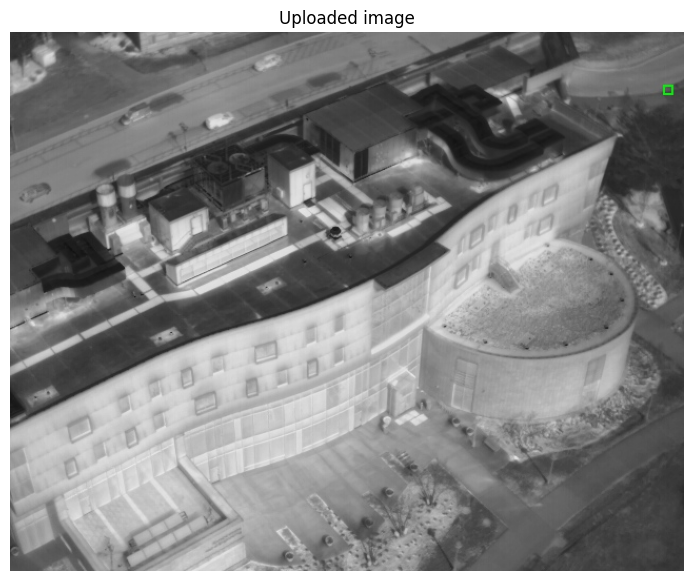

In [10]:

# ====================================
# 2) UPLOAD ONE IMAGE (RUN THIS CELL)
# ====================================
from google.colab import files
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()
assert len(uploaded) == 1, "Please upload exactly ONE image for this test."
IMAGE_PATH = list(uploaded.keys())[0]

print("Uploaded:", IMAGE_PATH)

img_bgr = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)
assert img_bgr is not None, "OpenCV could not read the uploaded image."

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,7))
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Uploaded image")
plt.show()

In [11]:

# ======================================
# 3) RUN ROBOFLOW WORKFLOW (RUN THIS)
# ======================================
import json
from inference_sdk import InferenceHTTPClient

client = InferenceHTTPClient(
    api_url="https://serverless.roboflow.com",
    api_key=ROBOFLOW_API_KEY,
)

result = client.run_workflow(
    workspace_name=WORKSPACE_NAME,
    workflow_id=WORKFLOW_ID,
    images={"image": IMAGE_PATH},
    use_cache=True,
)

print("Top-level keys:", list(result.keys()) if isinstance(result, dict) else type(result))
print(json.dumps(result, indent=2)[:2000], "\n...")

Top-level keys: <class 'list'>
[
  {
    "predictions": {
      "image": {
        "width": 640,
        "height": 512
      },
      "predictions": [
        {
          "width": 183.0,
          "height": 105.0,
          "x": 501.5,
          "y": 250.5,
          "confidence": 0.53125,
          "class_id": 0,
          "class": "roof",
          "detection_id": "55cde2e9-8a81-40dc-91e3-f0eae514a9d8",
          "parent_id": "image",
          "rle_mask": {
            "size": [
              512,
              640
            ],
            "counts": "aX]66h?4M2N3M101O0N201N1N2O2N101N100O2M3N1O2N2N100O1O2N100O1O1O2N1O1O101M2O1O100O001O100jAXNS>k110O001O10O001O011N1O00001O001O010O1O1O1O1O000000O100\\O\\NkBe1S=dNeB]1Z=eNdB\\1[=iN`BX1_=f0M10101N1O1O1O1O10000O10001N100O1O010O2O0O100O100O010O10000KQMWCQ3h<310O100O010001O0O100O1O1010O00000010O010O0O101O0000000O10001N2N1010OM4YMlB_2U=aMmB]2[=0O10ON2101O0001O01N101N1O20O1ON2SN[BY10_Nf=6[B[1O_Nf=6[B[1O_Ng=6YB`1i=_NWB`1l=91N102K4GmAbNU>\\1mA

In [12]:

# =======================================================
# 4) PARSE PREDICTIONS (MASKS/POLYGONS PREFERRED; BOXES OK)
# =======================================================
import numpy as np
import cv2
import base64, io
from PIL import Image
from pycocotools import mask as mask_utils

H, W = img_rgb.shape[:2]

def _safe_int(x):
    try:
        return int(round(float(x)))
    except Exception:
        return None

def decode_any_mask(pred, H, W):
    # Try COCO RLE first: pred["segmentation"]["counts"]
    seg = pred.get("segmentation") or pred.get("mask") or pred.get("rle")
    if isinstance(seg, dict) and "counts" in seg:
        rle = seg
        if "size" not in rle:
            rle = dict(rle)
            rle["size"] = [H, W]
        try:
            m = mask_utils.decode(rle)
            if m.ndim == 3:
                m = m[..., 0]
            return (m > 0).astype(np.uint8)
        except Exception:
            pass

    # Polygon points: pred["points"] or pred["polygon"]
    pts = pred.get("points") or pred.get("polygon") or pred.get("segmentation_polygon")
    if isinstance(pts, list) and len(pts) > 2:
        try:
            if isinstance(pts[0], dict) and "x" in pts[0] and "y" in pts[0]:
                poly = np.array([[p["x"], p["y"]] for p in pts], dtype=np.int32)
            else:
                poly = np.array(pts, dtype=np.int32)
            poly = poly.reshape((-1, 1, 2))
            m = np.zeros((H, W), dtype=np.uint8)
            cv2.fillPoly(m, [poly], 1)
            return m
        except Exception:
            pass

    # Base64 mask image (rare)
    b64 = pred.get("mask_base64") or pred.get("maskImage") or pred.get("mask_image_base64")
    if isinstance(b64, str) and len(b64) > 50:
        try:
            raw = base64.b64decode(b64)
            pil = Image.open(io.BytesIO(raw)).convert("L")
            m = np.array(pil)
            m = cv2.resize(m, (W, H), interpolation=cv2.INTER_NEAREST)
            return (m > 0).astype(np.uint8)
        except Exception:
            pass

    return None

def decode_bbox_mask(pred, H, W):
    # Format A: x,y,w,h centered
    if all(k in pred for k in ["x", "y", "width", "height"]):
        x, y, w, h = pred["x"], pred["y"], pred["width"], pred["height"]
        x0, y0 = _safe_int(x - w/2), _safe_int(y - h/2)
        x1, y1 = _safe_int(x + w/2), _safe_int(y + h/2)
    # Format B: x_min,y_min,x_max,y_max
    elif all(k in pred for k in ["x_min", "y_min", "x_max", "y_max"]):
        x0, y0, x1, y1 = map(_safe_int, [pred["x_min"], pred["y_min"], pred["x_max"], pred["y_max"]])
    else:
        return None

    if None in [x0, y0, x1, y1]:
        return None

    x0, y0 = max(0, x0), max(0, y0)
    x1, y1 = min(W-1, x1), min(H-1, y1)
    if x1 <= x0 or y1 <= y0:
        return None

    m = np.zeros((H, W), dtype=np.uint8)
    m[y0:y1, x0:x1] = 1
    return m

def find_prediction_dicts(obj):
    preds = []
    if isinstance(obj, dict):
        if "predictions" in obj and isinstance(obj["predictions"], list):
            for p in obj["predictions"]:
                if isinstance(p, dict):
                    preds.append(p)
        for v in obj.values():
            preds.extend(find_prediction_dicts(v))
    elif isinstance(obj, list):
        for it in obj:
            preds.extend(find_prediction_dicts(it))
    return preds

raw_preds = find_prediction_dicts(result)
print("Raw predictions found:", len(raw_preds))

preds = []
for p in raw_preds:
    cls = p.get("class") or p.get("label") or p.get("category") or "unknown"
    conf = p.get("confidence", p.get("score", 1.0))
    try:
        conf = float(conf)
    except Exception:
        conf = 1.0

    if conf < MIN_CONF:
        continue

    m = decode_any_mask(p, H, W)
    if m is None:
        m = decode_bbox_mask(p, H, W)

    preds.append({"class": str(cls), "confidence": conf, "mask": m, "raw": p})

print("Filtered predictions kept:", len(preds))
print("Classes:", sorted(set([p["class"] for p in preds])))

Raw predictions found: 39
Filtered predictions kept: 39
Classes: ['Window', 'roof']


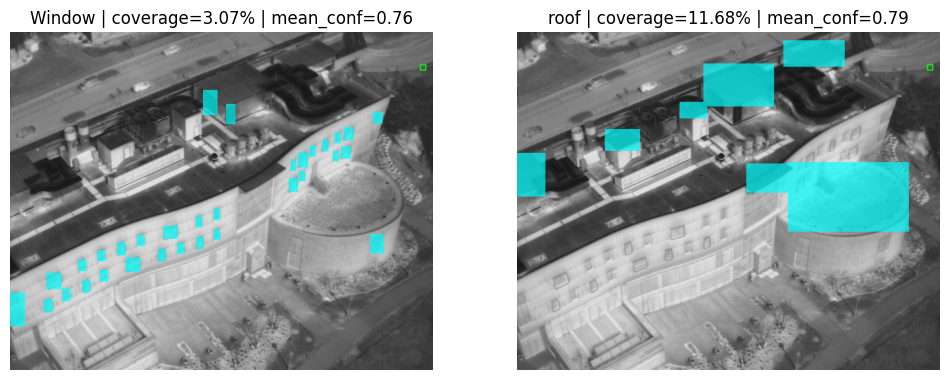

In [13]:

# ==========================================
# 5) MERGE INTO PER-CLASS MASKS + VISUALIZE
# ==========================================
import numpy as np
import matplotlib.pyplot as plt

H, W = img_rgb.shape[:2]

class_masks = {}
class_confs = {}

for p in preds:
    cls = p["class"]
    m = p["mask"]
    if m is None:
        continue
    if cls not in class_masks:
        class_masks[cls] = np.zeros((H, W), dtype=np.uint8)
        class_confs[cls] = []
    class_masks[cls] = np.maximum(class_masks[cls], (m > 0).astype(np.uint8))
    class_confs[cls].append(p["confidence"])

def show_mask_grid(img_rgb, masks_dict, max_cols=2):
    keys = sorted(masks_dict.keys())
    if len(keys) == 0:
        print("No masks available to show.")
        return

    n = len(keys)
    cols = min(max_cols, n)
    rows = int(np.ceil(n / cols))

    plt.figure(figsize=(6*cols, 6*rows))
    for i, k in enumerate(keys):
        m = masks_dict[k]
        overlay1 = img_rgb.copy()
        overlay1[m.astype(bool)] = (overlay1[m.astype(bool)] * 0.3 + np.array([0,255,255]) * 0.7).astype(np.uint8)

        plt.subplot(rows, cols, i+1)
        plt.imshow(overlay1)
        cover = 100.0 * m.mean()
        cmean = float(np.mean(class_confs.get(k, [np.nan])))
        plt.title(f"{k} | coverage={cover:.2f}% | mean_conf={cmean:.2f}")
        plt.axis("off")
    plt.show()

show_mask_grid(img_rgb, class_masks, max_cols=2)

In [14]:

# =====================================================
# 6) OPTIONAL: DERIVE WALL = BUILDING - ROOF - WINDOW
# =====================================================
import numpy as np
import matplotlib.pyplot as plt

BUILDING_NAME = "Building"  # update if needed
ROOF_NAME     = "Roof"
WINDOW_NAME   = "Window"

def get_mask_ci(name):
    for k in class_masks.keys():
        if k.lower() == name.lower():
            return class_masks[k]
    return None

building = get_mask_ci(BUILDING_NAME)
roof     = get_mask_ci(ROOF_NAME)
window   = get_mask_ci(WINDOW_NAME)

if building is not None:
    roof_m = roof if roof is not None else np.zeros_like(building)
    win_m  = window if window is not None else np.zeros_like(building)
    wall = (building.astype(bool) & (~roof_m.astype(bool)) & (~win_m.astype(bool))).astype(np.uint8)
    class_masks["_DERIVED_WALL"] = wall

    plt.figure(figsize=(10,7))
    overlay2 = img_rgb.copy()
    overlay2[wall.astype(bool)] = (overlay2[wall.astype(bool)] * 0.3 + np.array([255,255,0]) * 0.7).astype(np.uint8)
    plt.imshow(overlay2)
    plt.axis("off")
    plt.title("Derived wall overlay (_DERIVED_WALL)")
    plt.show()
else:
    print("No Building mask found. Add a 'Building (target)' class for cleaner walls.")

No Building mask found. Add a 'Building (target)' class for cleaner walls.


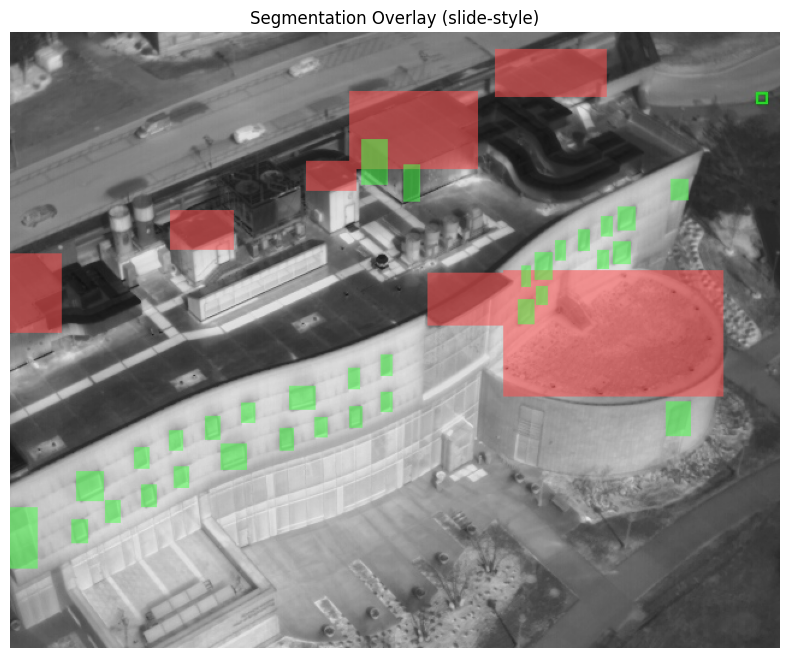

Legend (class, RGB, coverage%):
            roof  (255, 80, 80)  coverage=11.68%
          Window  (80, 255, 80)  coverage=3.07%


In [16]:

# =========================================
# 7) SINGLE OVERLAY (SLIDE-STYLE OUTPUT)
# =========================================
import numpy as np
import matplotlib.pyplot as plt
import cv2

ORDER = ["Roof", "Window", "_DERIVED_WALL", "Wall", "Building"]
ALPHA = 0.55

def find_key_ci(name):
    for kk in class_masks.keys():
        if kk.lower() == name.lower():
            return kk
    return None

order_existing = [find_key_ci(k) for k in ORDER]
order_existing = [k for k in order_existing if k is not None]
if not order_existing:
    order_existing = sorted(class_masks.keys())

palette = [
    (255,  80,  80),
    ( 80, 255,  80),
    ( 80, 200, 255),
    (255, 220,  80),
    (200,  80, 255),
]

overlay = img_rgb.copy()
legend_items = []

for i, key in enumerate(order_existing):
    m = class_masks[key]
    color = palette[i % len(palette)]
    mb = m.astype(bool)
    overlay[mb] = (overlay[mb] * (1-ALPHA) + np.array(color) * ALPHA).astype(np.uint8)
    legend_items.append((key, color, float(100.0*m.mean())))

plt.figure(figsize=(12,8))
plt.imshow(overlay)
plt.axis("off")
plt.title("Segmentation Overlay (slide-style)")
plt.show()

print("Legend (class, RGB, coverage%):")
for k,c,cov in legend_items:
    print(f"  {k:>14s}  {c}  coverage={cov:.2f}%")

In [9]:

# =========================================
# 8) EXPORT MASKS + SUMMARY (DOWNLOADABLE)
# =========================================
import os, json, zipfile
from datetime import datetime
import cv2
import numpy as np
from google.colab import files

out_dir = "roboflow_outputs"
os.makedirs(out_dir, exist_ok=True)

overlay_path = os.path.join(out_dir, "overlay.png")
cv2.imwrite(overlay_path, cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))

mask_paths = []
for k, m in class_masks.items():
    p = os.path.join(out_dir, f"mask__{k.replace(' ','_')}.png")
    cv2.imwrite(p, (m*255).astype(np.uint8))
    mask_paths.append(p)

summary = {
    "image": IMAGE_PATH,
    "height": int(H),
    "width": int(W),
    "min_conf": float(MIN_CONF),
    "classes": {k: {"coverage_pct": float(100.0*class_masks[k].mean())} for k in class_masks.keys()},
    "num_predictions_kept": int(len(preds)),
    "notes": "Best walls: add 'Building (target)' then derive wall = building - roof - window."
}
summary_path = os.path.join(out_dir, "summary.json")
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

zip_name = f"roboflow_outputs_{datetime.now().strftime('%Y%m%d_%H%M%S')}.zip"
with zipfile.ZipFile(zip_name, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for fn in [overlay_path, summary_path] + mask_paths:
        z.write(fn, arcname=os.path.join(out_dir, os.path.basename(fn)))

print("Wrote:", zip_name)
files.download(zip_name)

Wrote: roboflow_outputs_20260103_003053.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>